In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

DATA_DIR = Path("../data")

sales = pd.read_csv(DATA_DIR / "sales_train_validation.csv")
calendar = pd.read_csv(DATA_DIR / "calendar.csv")

print("Sales shape:", sales.shape)
print("Calendar shape:", calendar.shape)

Sales shape: (30490, 1919)
Calendar shape: (1969, 14)


In [2]:
# Select CA_1 and our top 20 products

ca1 = sales[sales["store_id"] == "CA_1"].copy()

day_cols = [c for c in sales.columns if c.startswith("d_")]

ca1["total_units"] = ca1[day_cols].sum(axis=1)

top_20 = (
    ca1
    .sort_values("total_units", ascending=False)
    .head(20)
)

top_20[["item_id", "dept_id", "cat_id", "total_units"]]

,item_id,dept_id,cat_id,total_units
2314,FOODS_3_090,FOODS_3,FOODS,127203
2810,FOODS_3_586,FOODS_3,FOODS,87691
2476,FOODS_3_252,FOODS_3,FOODS,74971
2344,FOODS_3_120,FOODS_3,FOODS,61899
2937,FOODS_3_714,FOODS_3,FOODS,54080
2811,FOODS_3_587,FOODS_3,FOODS,51717
3029,FOODS_3_808,FOODS_3,FOODS,46094
2023,FOODS_2_197,FOODS_2,FOODS,40698
2304,FOODS_3_080,FOODS_3,FOODS,39145
2779,FOODS_3_555,FOODS_3,FOODS,37871


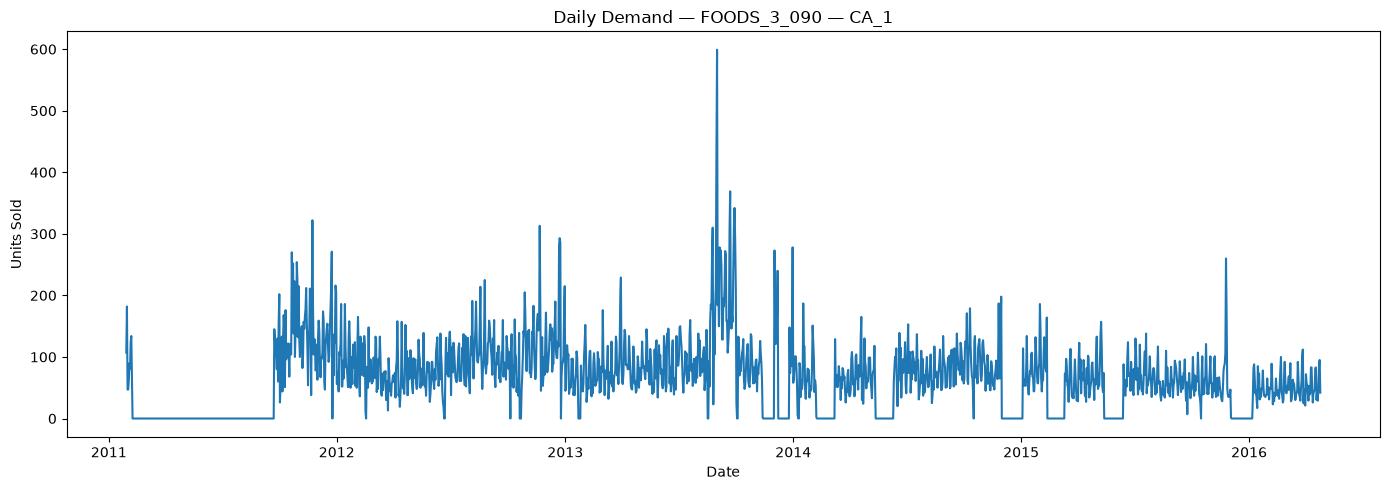

In [3]:
# Look at the highest-volume product

product_id = top_20.iloc[0]["item_id"]

product = top_20[top_20["item_id"] == product_id].iloc[0]

daily_sales = product[day_cols].astype(float).values

dates = pd.to_datetime(calendar["date"].iloc[:len(day_cols)])

plt.figure(figsize=(14, 5))

plt.plot(dates, daily_sales)

plt.title(f"Daily Demand — {product_id} — CA_1")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.tight_layout()
plt.show()

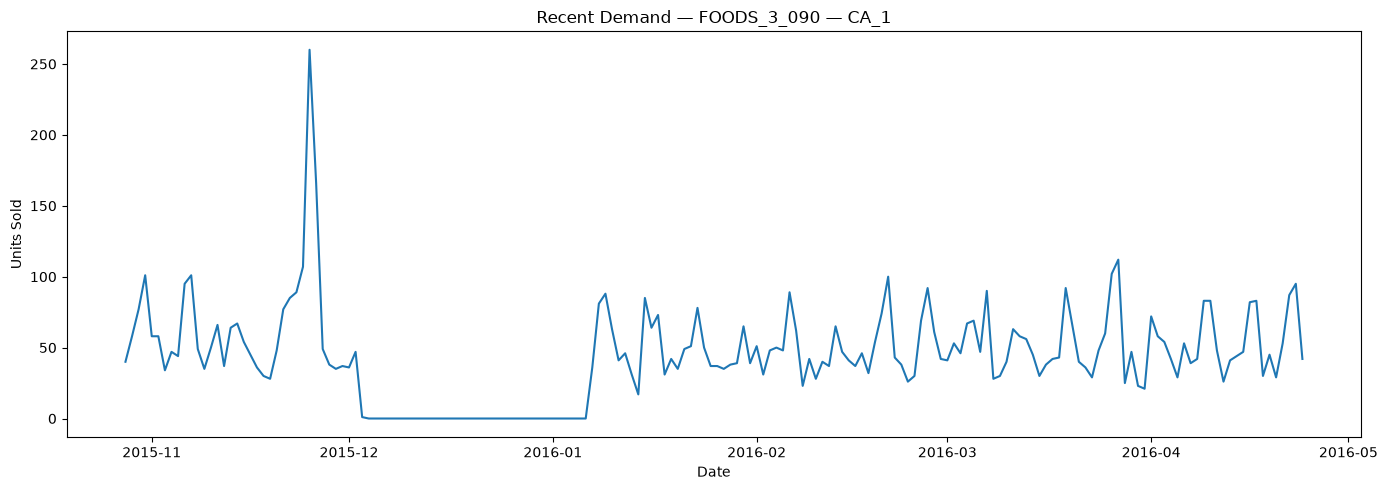

In [4]:
recent = 180

plt.figure(figsize=(14, 5))

plt.plot(
    dates[-recent:],
    daily_sales[-recent:]
)

plt.title(f"Recent Demand — {product_id} — CA_1")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.tight_layout()
plt.show()

In [5]:
# Annual demand for our selected product

product_df = pd.DataFrame({
    "date": dates,
    "sales": daily_sales
})

product_df["year"] = product_df["date"].dt.year

annual_demand = (
    product_df
    .groupby("year")["sales"]
    .agg(["sum", "mean", "max"])
    .round(2)
)

annual_demand

,sum,mean,max
year,,,
2011,14271.0,42.35,322.0
2012,33957.0,92.78,313.0
2013,33457.0,91.66,599.0
2014,21445.0,58.75,198.0
2015,18482.0,50.64,260.0
2016,5591.0,48.62,112.0


In [6]:
# Average demand by day of week

product_df["day_of_week"] = product_df["date"].dt.day_name()

weekly_pattern = (
    product_df
    .groupby("day_of_week")["sales"]
    .mean()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
    .round(2)
)

weekly_pattern

day_of_week
Monday       54.74
Tuesday      51.26
Wednesday    53.03
Thursday     55.33
Friday       74.90
Saturday     91.15
Sunday       84.90
Name: sales, dtype: float64

In [7]:
# Select the 20 products we'll use for Version 1

selected_items = top_20["item_id"].tolist()

selected_sales = ca1[
    ca1["item_id"].isin(selected_items)
].copy()

selected_sales = selected_sales[
    ["item_id", "dept_id", "cat_id", "store_id"] + day_cols
]

print("Selected series:", len(selected_sales))
print("Daily columns:", len(day_cols))

Selected series: 20
Daily columns: 1913


In [8]:
# Convert M5 wide format → long time-series format

sales_long = selected_sales.melt(
    id_vars=["item_id", "dept_id", "cat_id", "store_id"],
    value_vars=day_cols,
    var_name="d",
    value_name="sales"
)

print("Shape:", sales_long.shape)

sales_long.head()

Shape: (38260, 6)


,item_id,dept_id,cat_id,store_id,d,sales
0,FOODS_2_019,FOODS_2,FOODS,CA_1,d_1,15
1,FOODS_2_197,FOODS_2,FOODS,CA_1,d_1,38
2,FOODS_3_080,FOODS_3,FOODS,CA_1,d_1,33
3,FOODS_3_090,FOODS_3,FOODS,CA_1,d_1,107
4,FOODS_3_099,FOODS_3,FOODS,CA_1,d_1,0


In [9]:
# Attach calendar information

calendar_small = calendar[
    ["d", "date", "weekday", "wday", "month", "year",
     "event_name_1", "event_type_1"]
].copy()

sales_long = sales_long.merge(
    calendar_small,
    on="d",
    how="left"
)

sales_long["date"] = pd.to_datetime(sales_long["date"])

sales_long.head()

,item_id,dept_id,cat_id,store_id,d,sales,date,weekday,wday,month,year,event_name_1,event_type_1
0,FOODS_2_019,FOODS_2,FOODS,CA_1,d_1,15,2011-01-29,Saturday,1,1,2011,NaN,NaN
1,FOODS_2_197,FOODS_2,FOODS,CA_1,d_1,38,2011-01-29,Saturday,1,1,2011,NaN,NaN
2,FOODS_3_080,FOODS_3,FOODS,CA_1,d_1,33,2011-01-29,Saturday,1,1,2011,NaN,NaN
3,FOODS_3_090,FOODS_3,FOODS,CA_1,d_1,107,2011-01-29,Saturday,1,1,2011,NaN,NaN
4,FOODS_3_099,FOODS_3,FOODS,CA_1,d_1,0,2011-01-29,Saturday,1,1,2011,NaN,NaN


In [10]:
# Make sure each product's observations are in chronological order

sales_long = sales_long.sort_values(
    ["item_id", "date"]
).reset_index(drop=True)

sales_long.head(10)

,item_id,dept_id,cat_id,store_id,d,sales,date,weekday,wday,month,year,event_name_1,event_type_1
0,FOODS_2_019,FOODS_2,FOODS,CA_1,d_1,15,2011-01-29,Saturday,1,1,2011,NaN,NaN
1,FOODS_2_019,FOODS_2,FOODS,CA_1,d_2,27,2011-01-30,Sunday,2,1,2011,NaN,NaN
2,FOODS_2_019,FOODS_2,FOODS,CA_1,d_3,18,2011-01-31,Monday,3,1,2011,NaN,NaN
3,FOODS_2_019,FOODS_2,FOODS,CA_1,d_4,29,2011-02-01,Tuesday,4,2,2011,NaN,NaN
4,FOODS_2_019,FOODS_2,FOODS,CA_1,d_5,23,2011-02-02,Wednesday,5,2,2011,NaN,NaN
5,FOODS_2_019,FOODS_2,FOODS,CA_1,d_6,20,2011-02-03,Thursday,6,2,2011,NaN,NaN
6,FOODS_2_019,FOODS_2,FOODS,CA_1,d_7,2,2011-02-04,Friday,7,2,2011,NaN,NaN
7,FOODS_2_019,FOODS_2,FOODS,CA_1,d_8,2,2011-02-05,Saturday,1,2,2011,NaN,NaN
8,FOODS_2_019,FOODS_2,FOODS,CA_1,d_9,44,2011-02-06,Sunday,2,2,2011,SuperBowl,Sporting
9,FOODS_2_019,FOODS_2,FOODS,CA_1,d_10,14,2011-02-07,Monday,3,2,2011,NaN,NaN


In [11]:
# Previous week's demand

sales_long["lag_7"] = (
    sales_long
    .groupby("item_id")["sales"]
    .shift(7)
)

sales_long[
    ["item_id", "date", "sales", "lag_7"]
].head(15)

,item_id,date,sales,lag_7
0,FOODS_2_019,2011-01-29,15,NaN
1,FOODS_2_019,2011-01-30,27,NaN
2,FOODS_2_019,2011-01-31,18,NaN
3,FOODS_2_019,2011-02-01,29,NaN
4,FOODS_2_019,2011-02-02,23,NaN
5,FOODS_2_019,2011-02-03,20,NaN
6,FOODS_2_019,2011-02-04,2,NaN
7,FOODS_2_019,2011-02-05,2,15.0
8,FOODS_2_019,2011-02-06,44,27.0
9,FOODS_2_019,2011-02-07,14,18.0


In [12]:
# Define our first 28-day validation period

validation_days = 28

max_date = sales_long["date"].max()

validation_start = (
    max_date - pd.Timedelta(days=validation_days - 1)
)

train = sales_long[
    sales_long["date"] < validation_start
].copy()

validation = sales_long[
    sales_long["date"] >= validation_start
].copy()

print("Training period:")
print(train["date"].min(), "→", train["date"].max())

print("\nValidation period:")
print(validation["date"].min(), "→", validation["date"].max())

print("\nRows:")
print("Train:", len(train))
print("Validation:", len(validation))

Training period:
2011-01-29 00:00:00 → 2016-03-27 00:00:00

Validation period:
2016-03-28 00:00:00 → 2016-04-24 00:00:00

Rows:
Train: 37700
Validation: 560


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

validation = validation.dropna(subset=["lag_7"])

mae = mean_absolute_error(
    validation["sales"],
    validation["lag_7"]
)

rmse = np.sqrt(
    mean_squared_error(
        validation["sales"],
        validation["lag_7"]
    )
)

print(f"Seasonal Naive MAE:  {mae:.2f}")
print(f"Seasonal Naive RMSE: {rmse:.2f}")

Seasonal Naive MAE:  8.00
Seasonal Naive RMSE: 13.37


In [14]:
# Walk-forward validation for the seasonal-naive baseline

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

max_date = sales_long["date"].max()

folds = [
    {
        "name": "Fold 1",
        "validation_end": max_date - pd.Timedelta(days=56)
    },
    {
        "name": "Fold 2",
        "validation_end": max_date - pd.Timedelta(days=28)
    },
    {
        "name": "Fold 3",
        "validation_end": max_date
    },
]

results = []

for fold in folds:
    validation_end = fold["validation_end"]
    validation_start = validation_end - pd.Timedelta(days=27)

    validation = sales_long[
        (sales_long["date"] >= validation_start) &
        (sales_long["date"] <= validation_end)
    ].copy()

    validation = validation.dropna(subset=["lag_7"])

    mae = mean_absolute_error(
        validation["sales"],
        validation["lag_7"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            validation["sales"],
            validation["lag_7"]
        )
    )

    results.append({
        "fold": fold["name"],
        "validation_start": validation_start,
        "validation_end": validation_end,
        "MAE": mae,
        "RMSE": rmse
    })

walk_forward_results = pd.DataFrame(results)

walk_forward_results

,fold,validation_start,validation_end,MAE,RMSE
0,Fold 1,2016-02-01,2016-02-28,8.505357,13.389028
1,Fold 2,2016-02-29,2016-03-27,7.946429,13.256535
2,Fold 3,2016-03-28,2016-04-24,8.001786,13.370076


In [15]:
print(
    "Average MAE:",
    walk_forward_results["MAE"].mean().round(2)
)

print(
    "Average RMSE:",
    walk_forward_results["RMSE"].mean().round(2)
)

Average MAE: 8.15
Average RMSE: 13.34


In [16]:
# Create time-series features

sales_long = sales_long.sort_values(
    ["item_id", "date"]
).reset_index(drop=True)

grouped_sales = sales_long.groupby("item_id")["sales"]

# Lag features
sales_long["lag_1"] = grouped_sales.shift(1)
sales_long["lag_7"] = grouped_sales.shift(7)
sales_long["lag_28"] = grouped_sales.shift(28)

# Rolling features based ONLY on past observations
sales_long["rolling_mean_7"] = (
    grouped_sales
    .shift(1)
    .rolling(7)
    .mean()
    .reset_index(level=0, drop=True)
)

sales_long["rolling_mean_28"] = (
    grouped_sales
    .shift(1)
    .rolling(28)
    .mean()
    .reset_index(level=0, drop=True)
)

sales_long["rolling_std_28"] = (
    grouped_sales
    .shift(1)
    .rolling(28)
    .std()
    .reset_index(level=0, drop=True)
)

print(
    sales_long[
        [
            "item_id",
            "date",
            "sales",
            "lag_1",
            "lag_7",
            "lag_28",
            "rolling_mean_7",
            "rolling_mean_28",
            "rolling_std_28",
        ]
    ].tail(10)
)

           item_id       date  sales  lag_1  lag_7  lag_28  rolling_mean_7  \
38250  FOODS_3_808 2016-04-15      0    0.0    0.0     0.0             0.0   
38251  FOODS_3_808 2016-04-16      0    0.0    0.0     0.0             0.0   
38252  FOODS_3_808 2016-04-17      0    0.0    0.0     0.0             0.0   
38253  FOODS_3_808 2016-04-18      0    0.0    0.0     0.0             0.0   
38254  FOODS_3_808 2016-04-19      0    0.0    0.0     0.0             0.0   
38255  FOODS_3_808 2016-04-20      0    0.0    0.0     0.0             0.0   
38256  FOODS_3_808 2016-04-21      0    0.0    0.0     0.0             0.0   
38257  FOODS_3_808 2016-04-22      0    0.0    0.0     0.0             0.0   
38258  FOODS_3_808 2016-04-23      0    0.0    0.0    12.0             0.0   
38259  FOODS_3_808 2016-04-24      0    0.0    0.0     3.0             0.0   

       rolling_mean_28  rolling_std_28  
38250         1.928571        4.387934  
38251         1.928571        4.387934  
38252         1.92

In [17]:
# Calendar features

sales_long["day_of_week"] = sales_long["date"].dt.dayofweek
sales_long["month"] = sales_long["date"].dt.month
sales_long["week_of_year"] = sales_long["date"].dt.isocalendar().week.astype(int)
sales_long["is_weekend"] = (
    sales_long["day_of_week"] >= 5
).astype(int)

sales_long[
    [
        "date",
        "day_of_week",
        "month",
        "week_of_year",
        "is_weekend"
    ]
].head(10)

,date,day_of_week,month,week_of_year,is_weekend
0,2011-01-29,5,1,4,1
1,2011-01-30,6,1,4,1
2,2011-01-31,0,1,5,0
3,2011-02-01,1,2,5,0
4,2011-02-02,2,2,5,0
5,2011-02-03,3,2,5,0
6,2011-02-04,4,2,5,0
7,2011-02-05,5,2,5,1
8,2011-02-06,6,2,5,1
9,2011-02-07,0,2,6,0


In [18]:
# Remove rows where we don't yet have enough historical information

feature_columns = [
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_28",
    "day_of_week",
    "month",
    "week_of_year",
    "is_weekend",
]

model_data = sales_long.dropna(
    subset=feature_columns
).copy()

print("Original rows:", len(sales_long))
print("Model rows:", len(model_data))
print("Rows removed:", len(sales_long) - len(model_data))

Original rows: 38260
Model rows: 37700
Rows removed: 560


In [19]:
train_end = "2016-03-27"

train_data = model_data[
    model_data["date"] <= train_end
].copy()

valid_data = model_data[
    model_data["date"] > train_end
].copy()

print("Train rows:", len(train_data))
print("Validation rows:", len(valid_data))
print("Train end:", train_data["date"].max())
print("Validation start:", valid_data["date"].min())
print("Validation end:", valid_data["date"].max())

Train rows: 37140
Validation rows: 560
Train end: 2016-03-27 00:00:00
Validation start: 2016-03-28 00:00:00
Validation end: 2016-04-24 00:00:00


In [20]:
X_train = train_data[feature_columns]
y_train = train_data["sales"]

X_valid = valid_data[feature_columns]
y_valid = valid_data["sales"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_valid:", X_valid.shape)
print("y_valid:", y_valid.shape)

X_train: (37140, 10)
y_train: (37140,)
X_valid: (560, 10)
y_valid: (560,)


In [21]:
from sklearn.ensemble import HistGradientBoostingRegressor

model = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


In [22]:
valid_predictions = model.predict(X_valid)

print("First 10 predictions:")
print(valid_predictions[:10])

print("\nPrediction range:")
print("Min:", valid_predictions.min())
print("Max:", valid_predictions.max())

First 10 predictions:
[13.18142808 13.07022201 13.6606955  12.61391597 13.016393   14.9166167
 21.04290683 14.9333233  14.38582145 12.0609711 ]

Prediction range:
Min: 0.8947752784630282
Max: 92.95930808896482


In [23]:
def recursive_forecast(model, history, future_dates):
    """
    Generate a multi-day recursive forecast.

    history:
        DataFrame containing known historical sales for each item.
        Must contain: item_id, date, sales

    future_dates:
        Dates to forecast.
    """

    history = history[["item_id", "date", "sales"]].copy()
    history = history.sort_values(["item_id", "date"])

    predictions = []

    items = history["item_id"].unique()

    for item_id in items:
        item_history = history[
            history["item_id"] == item_id
        ].copy()

        item_history = item_history.sort_values("date")

        for forecast_date in future_dates:

            sales_values = item_history["sales"].values

            # Build lag features from known history/predictions
            lag_1 = sales_values[-1]
            lag_7 = sales_values[-7]
            lag_28 = sales_values[-28:]

            rolling_mean_7 = sales_values[-7:].mean()
            rolling_mean_28 = sales_values[-28:].mean()
            rolling_std_28 = sales_values[-28:].std()

            day_of_week = forecast_date.dayofweek
            month = forecast_date.month
            week_of_year = forecast_date.isocalendar().week
            is_weekend = int(day_of_week >= 5)

            feature_row = pd.DataFrame([{
                "lag_1": lag_1,
                "lag_7": lag_7,
                "lag_28": lag_28[0],
                "rolling_mean_7": rolling_mean_7,
                "rolling_mean_28": rolling_mean_28,
                "rolling_std_28": rolling_std_28,
                "day_of_week": day_of_week,
                "month": month,
                "week_of_year": int(week_of_year),
                "is_weekend": is_weekend,
            }])

            prediction = model.predict(feature_row)[0]

            # Demand cannot be negative
            prediction = max(0, prediction)

            predictions.append({
                "item_id": item_id,
                "date": forecast_date,
                "prediction": prediction
            })

            # Add prediction to history so it can be used
            # for the next forecast day
            item_history = pd.concat([
                item_history,
                pd.DataFrame([{
                    "item_id": item_id,
                    "date": forecast_date,
                    "sales": prediction
                }])
            ], ignore_index=True)

    return pd.DataFrame(predictions)

In [24]:
forecast_dates = pd.date_range(
    start="2016-03-28",
    end="2016-04-24",
    freq="D"
)

history = sales_long[
    sales_long["date"] <= "2016-03-27"
][
    ["item_id", "date", "sales"]
].copy()

recursive_predictions = recursive_forecast(
    model=model,
    history=history,
    future_dates=forecast_dates
)

print(recursive_predictions.head(10))
print("\nRows:", len(recursive_predictions))

       item_id       date  prediction
0  FOODS_2_019 2016-03-28   13.098585
1  FOODS_2_019 2016-03-29   12.856362
2  FOODS_2_019 2016-03-30   13.075191
3  FOODS_2_019 2016-03-31   13.243560
4  FOODS_2_019 2016-04-01   14.518739
5  FOODS_2_019 2016-04-02   19.054389
6  FOODS_2_019 2016-04-03   21.862231
7  FOODS_2_019 2016-04-04   14.465224
8  FOODS_2_019 2016-04-05   13.852638
9  FOODS_2_019 2016-04-06   13.655223

Rows: 560


In [25]:
recursive_predictions["date"] = pd.to_datetime(
    recursive_predictions["date"]
)

comparison = recursive_predictions.merge(
    valid_data[["item_id", "date", "sales"]],
    on=["item_id", "date"],
    how="left"
)

print(comparison.head())

print("\nActual total:", comparison["sales"].sum())
print("Predicted total:", comparison["prediction"].sum())

       item_id       date  prediction  sales
0  FOODS_2_019 2016-03-28   13.098585     14
1  FOODS_2_019 2016-03-29   12.856362     18
2  FOODS_2_019 2016-03-30   13.075191      8
3  FOODS_2_019 2016-03-31   13.243560     10
4  FOODS_2_019 2016-04-01   14.518739      8

Actual total: 11030
Predicted total: 12646.781102232873


In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(
    comparison["sales"],
    comparison["prediction"]
)

rmse = np.sqrt(
    mean_squared_error(
        comparison["sales"],
        comparison["prediction"]
    )
)

print(f"Recursive ML MAE:  {mae:.2f}")
print(f"Recursive ML RMSE: {rmse:.2f}")

Recursive ML MAE:  7.61
Recursive ML RMSE: 10.68


In [27]:
baseline_mae = 8.00
baseline_rmse = 13.37

mae_improvement = (
    (baseline_mae - mae) / baseline_mae
) * 100

rmse_improvement = (
    (baseline_rmse - rmse) / baseline_rmse
) * 100

print(f"Baseline MAE:      {baseline_mae:.2f}")
print(f"ML MAE:            {mae:.2f}")
print(f"MAE change:        {mae_improvement:.2f}%")

print()

print(f"Baseline RMSE:     {baseline_rmse:.2f}")
print(f"ML RMSE:           {rmse:.2f}")
print(f"RMSE change:       {rmse_improvement:.2f}%")

Baseline MAE:      8.00
ML MAE:            7.61
MAE change:        4.87%

Baseline RMSE:     13.37
ML RMSE:           10.68
RMSE change:       20.08%


In [28]:
prices = pd.read_csv(
    DATA_DIR / "sell_prices.csv"
)

prices.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [29]:
selected_prices = prices[
    (prices["store_id"] == "CA_1") &
    (prices["item_id"].isin(selected_items))
].copy()

print("Price rows:", len(selected_prices))
print(selected_prices.head())

Price rows: 5457
       store_id      item_id  wm_yr_wk  sell_price
424962     CA_1  FOODS_2_019     11101        2.98
424963     CA_1  FOODS_2_019     11102        2.98
424964     CA_1  FOODS_2_019     11103        2.98
424965     CA_1  FOODS_2_019     11104        2.98
424966     CA_1  FOODS_2_019     11105        2.98


In [30]:
calendar_price = calendar[
    ["d", "date", "wm_yr_wk"]
].copy()

calendar_price["date"] = pd.to_datetime(
    calendar_price["date"]
)

calendar_price.head()

,d,date,wm_yr_wk
0,d_1,2011-01-29,11101
1,d_2,2011-01-30,11101
2,d_3,2011-01-31,11101
3,d_4,2011-02-01,11101
4,d_5,2011-02-02,11101


In [31]:
sales_with_week = sales_long.merge(
    calendar_price[["date", "wm_yr_wk"]],
    on="date",
    how="left"
)

sales_with_week.head()

,item_id,dept_id,cat_id,store_id,d,sales,date,weekday,wday,month,...,lag_7,lag_1,lag_28,rolling_mean_7,rolling_mean_28,rolling_std_28,day_of_week,week_of_year,is_weekend,wm_yr_wk
0,FOODS_2_019,FOODS_2,FOODS,CA_1,d_1,15,2011-01-29,Saturday,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,5,4,1,11101
1,FOODS_2_019,FOODS_2,FOODS,CA_1,d_2,27,2011-01-30,Sunday,2,1,...,NaN,15.0,NaN,NaN,NaN,NaN,6,4,1,11101
2,FOODS_2_019,FOODS_2,FOODS,CA_1,d_3,18,2011-01-31,Monday,3,1,...,NaN,27.0,NaN,NaN,NaN,NaN,0,5,0,11101
3,FOODS_2_019,FOODS_2,FOODS,CA_1,d_4,29,2011-02-01,Tuesday,4,2,...,NaN,18.0,NaN,NaN,NaN,NaN,1,5,0,11101
4,FOODS_2_019,FOODS_2,FOODS,CA_1,d_5,23,2011-02-02,Wednesday,5,2,...,NaN,29.0,NaN,NaN,NaN,NaN,2,5,0,11101


In [32]:
sales_with_price = sales_with_week.merge(
    selected_prices[
        [
            "item_id",
            "wm_yr_wk",
            "sell_price"
        ]
    ],
    on=[
        "item_id",
        "wm_yr_wk"
    ],
    how="left"
)

sales_with_price.head()

,item_id,dept_id,cat_id,store_id,d,sales,date,weekday,wday,month,...,lag_1,lag_28,rolling_mean_7,rolling_mean_28,rolling_std_28,day_of_week,week_of_year,is_weekend,wm_yr_wk,sell_price
0,FOODS_2_019,FOODS_2,FOODS,CA_1,d_1,15,2011-01-29,Saturday,1,1,...,NaN,NaN,NaN,NaN,NaN,5,4,1,11101,2.98
1,FOODS_2_019,FOODS_2,FOODS,CA_1,d_2,27,2011-01-30,Sunday,2,1,...,15.0,NaN,NaN,NaN,NaN,6,4,1,11101,2.98
2,FOODS_2_019,FOODS_2,FOODS,CA_1,d_3,18,2011-01-31,Monday,3,1,...,27.0,NaN,NaN,NaN,NaN,0,5,0,11101,2.98
3,FOODS_2_019,FOODS_2,FOODS,CA_1,d_4,29,2011-02-01,Tuesday,4,2,...,18.0,NaN,NaN,NaN,NaN,1,5,0,11101,2.98
4,FOODS_2_019,FOODS_2,FOODS,CA_1,d_5,23,2011-02-02,Wednesday,5,2,...,29.0,NaN,NaN,NaN,NaN,2,5,0,11101,2.98


In [33]:
print(
    "Missing prices:",
    sales_with_price["sell_price"].isna().sum()
)

print(
    "Total rows:",
    len(sales_with_price)
)

Missing prices: 1281
Total rows: 38260


In [34]:
sales_with_price = sales_with_price.sort_values(
    ["item_id", "date"]
)

sales_with_price["price_change"] = (
    sales_with_price
    .groupby("item_id")["sell_price"]
    .pct_change()
)

sales_with_price[
    [
        "item_id",
        "date",
        "sell_price",
        "price_change"
    ]
].head(15)

,item_id,date,sell_price,price_change
0,FOODS_2_019,2011-01-29,2.98,NaN
1,FOODS_2_019,2011-01-30,2.98,0.0
2,FOODS_2_019,2011-01-31,2.98,0.0
3,FOODS_2_019,2011-02-01,2.98,0.0
4,FOODS_2_019,2011-02-02,2.98,0.0
5,FOODS_2_019,2011-02-03,2.98,0.0
6,FOODS_2_019,2011-02-04,2.98,0.0
7,FOODS_2_019,2011-02-05,2.98,0.0
8,FOODS_2_019,2011-02-06,2.98,0.0
9,FOODS_2_019,2011-02-07,2.98,0.0


In [35]:
sales_with_price["has_event"] = (
    sales_with_price["event_name_1"]
    .notna()
).astype(int)

sales_with_price[
    [
        "date",
        "event_name_1",
        "has_event"
    ]
].head(20)

,date,event_name_1,has_event
0,2011-01-29,NaN,0
1,2011-01-30,NaN,0
2,2011-01-31,NaN,0
3,2011-02-01,NaN,0
4,2011-02-02,NaN,0
5,2011-02-03,NaN,0
6,2011-02-04,NaN,0
7,2011-02-05,NaN,0
8,2011-02-06,SuperBowl,1
9,2011-02-07,NaN,0


In [36]:
price_features = [
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_28",
    "day_of_week",
    "month",
    "week_of_year",
    "is_weekend",
    "sell_price",
    "price_change",
    "has_event"
]

In [37]:
sales_with_price = sales_with_price.sort_values(
    ["item_id", "date"]
)

# Track missing prices before filling
sales_with_price["price_missing"] = (
    sales_with_price["sell_price"]
    .isna()
    .astype(int)
)

# Fill prices within each product
sales_with_price["sell_price"] = (
    sales_with_price
    .groupby("item_id")["sell_price"]
    .transform(
        lambda x: x.ffill().bfill()
    )
)

print(
    "Missing prices after filling:",
    sales_with_price["sell_price"].isna().sum()
)

Missing prices after filling: 0


In [38]:
sales_with_price["price_change"] = (
    sales_with_price
    .groupby("item_id")["sell_price"]
    .pct_change()
)

sales_with_price["price_change"] = (
    sales_with_price["price_change"]
    .fillna(0)
)

sales_with_price[
    [
        "item_id",
        "date",
        "sell_price",
        "price_change",
        "price_missing"
    ]
].head(20)

,item_id,date,sell_price,price_change,price_missing
0,FOODS_2_019,2011-01-29,2.98,0.0,0
1,FOODS_2_019,2011-01-30,2.98,0.0,0
2,FOODS_2_019,2011-01-31,2.98,0.0,0
3,FOODS_2_019,2011-02-01,2.98,0.0,0
4,FOODS_2_019,2011-02-02,2.98,0.0,0
5,FOODS_2_019,2011-02-03,2.98,0.0,0
6,FOODS_2_019,2011-02-04,2.98,0.0,0
7,FOODS_2_019,2011-02-05,2.98,0.0,0
8,FOODS_2_019,2011-02-06,2.98,0.0,0
9,FOODS_2_019,2011-02-07,2.98,0.0,0


In [39]:
sales_with_price = sales_with_price.sort_values(
    ["item_id", "date"]
)

grouped_sales = (
    sales_with_price
    .groupby("item_id")["sales"]
)

sales_with_price["lag_1"] = grouped_sales.shift(1)
sales_with_price["lag_7"] = grouped_sales.shift(7)
sales_with_price["lag_28"] = grouped_sales.shift(28)

sales_with_price["rolling_mean_7"] = (
    grouped_sales
    .shift(1)
    .rolling(7)
    .mean()
    .reset_index(level=0, drop=True)
)

sales_with_price["rolling_mean_28"] = (
    grouped_sales
    .shift(1)
    .rolling(28)
    .mean()
    .reset_index(level=0, drop=True)
)

sales_with_price["rolling_std_28"] = (
    grouped_sales
    .shift(1)
    .rolling(28)
    .std()
    .reset_index(level=0, drop=True)
)

In [40]:
price_feature_columns = [
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_28",
    "day_of_week",
    "month",
    "week_of_year",
    "is_weekend",
    "sell_price",
    "price_change",
    "price_missing",
    "has_event"
]


price_model_data = sales_with_price.dropna(
    subset=price_feature_columns
).copy()

print(price_model_data.shape)

(37700, 27)


In [41]:
train_end = "2016-03-27"

train_price = price_model_data[
    price_model_data["date"] <= train_end
].copy()

valid_price = price_model_data[
    price_model_data["date"] > train_end
].copy()

print("Train:", train_price.shape)
print("Validation:", valid_price.shape)

Train: (37140, 27)
Validation: (560, 27)


In [42]:
X_train_price = train_price[price_feature_columns]
y_train_price = train_price["sales"]

X_valid_price = valid_price[price_feature_columns]
y_valid_price = valid_price["sales"]

print(X_train_price.shape)
print(X_valid_price.shape)

(37140, 14)
(560, 14)


In [43]:
from sklearn.ensemble import HistGradientBoostingRegressor

price_model = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

price_model.fit(
    X_train_price,
    y_train_price
)

print("Price model trained.")

Price model trained.


In [44]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    price_model,
    X_valid_price,
    y_valid_price,
    n_repeats=5,
    random_state=42
)

importance_df = pd.DataFrame({
    "feature": X_valid_price.columns,
    "importance": importance.importances_mean
})

importance_df.sort_values(
    "importance",
    ascending=False
)

,feature,importance
0,lag_1,0.397901
3,rolling_mean_7,0.214752
6,day_of_week,0.134335
2,lag_28,0.007187
4,rolling_mean_28,0.006589
10,sell_price,0.004264
5,rolling_std_28,0.003547
7,month,0.000745
8,week_of_year,0.000576
9,is_weekend,0.000000


In [45]:
future_features = sales_with_price[
    [
        "item_id",
        "date",
        "sell_price",
        "price_change",
        "price_missing",
        "has_event"
    ]
].copy()

future_features = future_features[
    future_features["date"].between(
        "2016-03-28",
        "2016-04-24"
    )
]

print(future_features.shape)
print(future_features.head())

(560, 6)
          item_id       date  sell_price  price_change  price_missing  \
1885  FOODS_2_019 2016-03-28        3.42           0.0              0   
1886  FOODS_2_019 2016-03-29        3.42           0.0              0   
1887  FOODS_2_019 2016-03-30        3.42           0.0              0   
1888  FOODS_2_019 2016-03-31        3.42           0.0              0   
1889  FOODS_2_019 2016-04-01        3.42           0.0              0   

      has_event  
1885          0  
1886          0  
1887          0  
1888          0  
1889          0  


In [46]:
future_lookup = (
    future_features
    .set_index(["item_id", "date"])
    .to_dict("index")
)

print(len(future_lookup))

560


In [47]:
def recursive_forecast_v2(model, history, future_dates, future_lookup):
    """
    Generate a multi-day recursive forecast using
    demand history + future-known price/event features.
    """

    history = history[["item_id", "date", "sales"]].copy()
    history = history.sort_values(["item_id", "date"])

    predictions = []

    items = history["item_id"].unique()

    for item_id in items:

        item_history = history[
            history["item_id"] == item_id
        ].copy()

        item_history = item_history.sort_values("date")

        for forecast_date in future_dates:

            sales_values = item_history["sales"].values

            # -------------------------
            # Historical demand features
            # -------------------------

            lag_1 = sales_values[-1]
            lag_7 = sales_values[-7]
            lag_28 = sales_values[-28]

            rolling_mean_7 = sales_values[-7:].mean()
            rolling_mean_28 = sales_values[-28:].mean()
            rolling_std_28 = sales_values[-28:].std()

            # -------------------------
            # Calendar features
            # -------------------------

            day_of_week = forecast_date.dayofweek
            month = forecast_date.month
            week_of_year = int(forecast_date.isocalendar().week)
            is_weekend = int(day_of_week >= 5)

            # -------------------------
            # Future-known features
            # -------------------------

            future_row = future_lookup[
                (item_id, pd.Timestamp(forecast_date))
            ]

            sell_price = future_row["sell_price"]
            price_change = future_row["price_change"]
            price_missing = future_row["price_missing"]
            has_event = future_row["has_event"]

            # -------------------------
            # Model input
            # -------------------------

            feature_row = pd.DataFrame([{
                "lag_1": lag_1,
                "lag_7": lag_7,
                "lag_28": lag_28,
                "rolling_mean_7": rolling_mean_7,
                "rolling_mean_28": rolling_mean_28,
                "rolling_std_28": rolling_std_28,
                "day_of_week": day_of_week,
                "month": month,
                "week_of_year": week_of_year,
                "is_weekend": is_weekend,
                "sell_price": sell_price,
                "price_change": price_change,
                "price_missing": price_missing,
                "has_event": has_event,
            }])

            # Ensure exact training feature order
            feature_row = feature_row[price_feature_columns]

            prediction = model.predict(feature_row)[0]

            # Demand cannot be negative
            prediction = max(0, prediction)

            predictions.append({
                "item_id": item_id,
                "date": forecast_date,
                "prediction": prediction
            })

            # -------------------------
            # Feed prediction back into
            # history for next day
            # -------------------------

            item_history = pd.concat([
                item_history,
                pd.DataFrame([{
                    "item_id": item_id,
                    "date": forecast_date,
                    "sales": prediction
                }])
            ], ignore_index=True)

    return pd.DataFrame(predictions)

In [48]:
history_v2 = sales_with_price[
    sales_with_price["date"] <= "2016-03-27"
][
    ["item_id", "date", "sales"]
].copy()

recursive_predictions_v2 = recursive_forecast_v2(
    model=price_model,
    history=history_v2,
    future_dates=forecast_dates,
    future_lookup=future_lookup
)

print(recursive_predictions_v2.shape)
print(recursive_predictions_v2.head())

(560, 3)
       item_id       date  prediction
0  FOODS_2_019 2016-03-28   13.009986
1  FOODS_2_019 2016-03-29   12.717728
2  FOODS_2_019 2016-03-30   13.018602
3  FOODS_2_019 2016-03-31   13.074155
4  FOODS_2_019 2016-04-01   14.246916


In [49]:
actuals_v2 = sales_with_price[
    sales_with_price["date"].between(
        "2016-03-28",
        "2016-04-24"
    )
][
    ["item_id", "date", "sales"]
].copy()

comparison_v2 = recursive_predictions_v2.merge(
    actuals_v2,
    on=["item_id", "date"],
    how="left"
)

mae_v2 = mean_absolute_error(
    comparison_v2["sales"],
    comparison_v2["prediction"]
)

rmse_v2 = np.sqrt(
    mean_squared_error(
        comparison_v2["sales"],
        comparison_v2["prediction"]
    )
)

print("V2 MAE:", mae_v2)
print("V2 RMSE:", rmse_v2)

V2 MAE: 7.586427090391505
V2 RMSE: 10.739758786823552


In [50]:
baseline_mae = 8.00
baseline_rmse = 13.37

v1_mae = 7.61
v1_rmse = 10.68

print("Model comparison")
print("----------------")
print(f"Seasonal Naive MAE: {baseline_mae:.2f}")
print(f"Model V1 MAE:       {v1_mae:.2f}")
print(f"Model V2 MAE:       {mae_v2:.2f}")

print()

print(f"Seasonal Naive RMSE: {baseline_rmse:.2f}")
print(f"Model V1 RMSE:       {v1_rmse:.2f}")
print(f"Model V2 RMSE:       {rmse_v2:.2f}")

Model comparison
----------------
Seasonal Naive MAE: 8.00
Model V1 MAE:       7.61
Model V2 MAE:       7.59

Seasonal Naive RMSE: 13.37
Model V1 RMSE:       10.68
Model V2 RMSE:       10.74


In [51]:
mae_improvement_v1 = (
    (baseline_mae - v1_mae)
    / baseline_mae
    * 100
)

mae_improvement_v2 = (
    (baseline_mae - mae_v2)
    / baseline_mae
    * 100
)

rmse_improvement_v1 = (
    (baseline_rmse - v1_rmse)
    / baseline_rmse
    * 100
)

rmse_improvement_v2 = (
    (baseline_rmse - rmse_v2)
    / baseline_rmse
    * 100
)

print(f"V1 MAE improvement:  {mae_improvement_v1:.2f}%")
print(f"V2 MAE improvement:  {mae_improvement_v2:.2f}%")
print(f"V1 RMSE improvement: {rmse_improvement_v1:.2f}%")
print(f"V2 RMSE improvement: {rmse_improvement_v2:.2f}%")

V1 MAE improvement:  4.87%
V2 MAE improvement:  5.17%
V1 RMSE improvement: 20.12%
V2 RMSE improvement: 19.67%


In [52]:
def evaluate_forecast_window(
    model,
    sales_data,
    validation_start,
    validation_end
):
    """
    Evaluate a recursive 28-day forecast for one historical window.
    """

    validation_start = pd.Timestamp(validation_start)
    validation_end = pd.Timestamp(validation_end)

    # 28 days of history must exist before the forecast starts
    history_end = validation_start - pd.Timedelta(days=1)

    history = sales_data[
        sales_data["date"] <= history_end
    ][
        ["item_id", "date", "sales"]
    ].copy()

    future_dates = pd.date_range(
        validation_start,
        validation_end,
        freq="D"
    )

    predictions = recursive_forecast(
        model=model,
        history=history,
        future_dates=future_dates
    )

    actuals = sales_data[
        sales_data["date"].between(
            validation_start,
            validation_end
        )
    ][
        ["item_id", "date", "sales"]
    ].copy()

    comparison = predictions.merge(
        actuals,
        on=["item_id", "date"],
        how="left"
    )

    mae = mean_absolute_error(
        comparison["sales"],
        comparison["prediction"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            comparison["sales"],
            comparison["prediction"]
        )
    )

    return {
        "validation_start": validation_start,
        "validation_end": validation_end,
        "mae": mae,
        "rmse": rmse,
        "actual_total": comparison["sales"].sum(),
        "predicted_total": comparison["prediction"].sum()
    }

In [53]:
folds = [
    ("2016-02-01", "2016-02-28"),
    ("2016-02-29", "2016-03-27"),
    ("2016-03-28", "2016-04-24"),
]

walk_forward_results = []

for validation_start, validation_end in folds:

    result = evaluate_forecast_window(
        model=model,
        sales_data=sales_long,
        validation_start=validation_start,
        validation_end=validation_end
    )

    walk_forward_results.append(result)

walk_forward_results = pd.DataFrame(
    walk_forward_results
)

walk_forward_results

,validation_start,validation_end,mae,rmse,actual_total,predicted_total
0,2016-02-01,2016-02-28,7.514315,11.061817,11021,11267.629943
1,2016-02-29,2016-03-27,7.826249,11.012427,10340,11321.911298
2,2016-03-28,2016-04-24,7.610116,10.684714,11030,12646.781102


In [54]:
print(
    "Average MAE:",
    walk_forward_results["mae"].mean()
)

print(
    "Average RMSE:",
    walk_forward_results["rmse"].mean()
)

Average MAE: 7.650226825004558
Average RMSE: 10.919652516558623


In [55]:
walk_forward_results["total_error"] = (
    walk_forward_results["predicted_total"]
    - walk_forward_results["actual_total"]
)

walk_forward_results["total_error_pct"] = (
    walk_forward_results["total_error"]
    / walk_forward_results["actual_total"]
    * 100
)

walk_forward_results[
    [
        "validation_start",
        "validation_end",
        "actual_total",
        "predicted_total",
        "total_error",
        "total_error_pct"
    ]
]

,validation_start,validation_end,actual_total,predicted_total,total_error,total_error_pct
0,2016-02-01,2016-02-28,11021,11267.629943,246.629943,2.237818
1,2016-02-29,2016-03-27,10340,11321.911298,981.911298,9.496241
2,2016-03-28,2016-04-24,11030,12646.781102,1616.781102,14.658034


In [56]:
print(
    "Average MAE:",
    walk_forward_results["mae"].mean()
)

print(
    "Average RMSE:",
    walk_forward_results["rmse"].mean()
)

print(
    "Average total error:",
    walk_forward_results["total_error"].mean()
)

print(
    "Average total error %:",
    walk_forward_results["total_error_pct"].mean()
)

Average MAE: 7.650226825004558
Average RMSE: 10.919652516558623
Average total error: 948.4407813300617
Average total error %: 8.797364185925302


In [57]:
baseline_results = pd.DataFrame({
    "validation_start": [
        "2016-02-01",
        "2016-02-29",
        "2016-03-28"
    ],
    "validation_end": [
        "2016-02-28",
        "2016-03-27",
        "2016-04-24"
    ],
    "mae": [
        8.505357,
        7.946429,
        8.001786
    ],
    "rmse": [
        13.389028,
        13.256535,
        13.370076
    ]
})

print("Baseline average MAE:", baseline_results["mae"].mean())
print("Model average MAE:", walk_forward_results["mae"].mean())

print()

print("Baseline average RMSE:", baseline_results["rmse"].mean())
print("Model average RMSE:", walk_forward_results["rmse"].mean())

Baseline average MAE: 8.151190666666666
Model average MAE: 7.650226825004558

Baseline average RMSE: 13.338546333333333
Model average RMSE: 10.919652516558623


In [58]:
future_calendar = calendar[
    calendar["date"].between(
        "2016-04-25",
        "2016-05-22"
    )
][
    [
        "d",
        "date",
        "weekday",
        "wday",
        "month",
        "year",
        "event_name_1",
        "event_type_1"
    ]
].copy()

future_calendar["date"] = pd.to_datetime(
    future_calendar["date"]
)

print(future_calendar.shape)
print(future_calendar.head())
print(future_calendar.tail())

(28, 8)
           d       date    weekday  wday  month  year event_name_1  \
1913  d_1914 2016-04-25     Monday     3      4  2016          NaN   
1914  d_1915 2016-04-26    Tuesday     4      4  2016          NaN   
1915  d_1916 2016-04-27  Wednesday     5      4  2016          NaN   
1916  d_1917 2016-04-28   Thursday     6      4  2016          NaN   
1917  d_1918 2016-04-29     Friday     7      4  2016          NaN   

     event_type_1  
1913          NaN  
1914          NaN  
1915          NaN  
1916          NaN  
1917          NaN  
           d       date    weekday  wday  month  year event_name_1  \
1936  d_1937 2016-05-18  Wednesday     5      5  2016          NaN   
1937  d_1938 2016-05-19   Thursday     6      5  2016          NaN   
1938  d_1939 2016-05-20     Friday     7      5  2016          NaN   
1939  d_1940 2016-05-21   Saturday     1      5  2016          NaN   
1940  d_1941 2016-05-22     Sunday     2      5  2016          NaN   

     event_type_1  
1936      

In [59]:
def forecast_future_28_days(
    model,
    history,
    future_dates
):
    """
    Generate a recursive 28-day forecast for all items.
    """

    history = history[
        ["item_id", "date", "sales"]
    ].copy()

    history = history.sort_values(
        ["item_id", "date"]
    )

    predictions = []

    items = history["item_id"].unique()

    for item_id in items:

        item_history = history[
            history["item_id"] == item_id
        ].copy()

        item_history = item_history.sort_values("date")

        for forecast_date in future_dates:

            sales_values = item_history["sales"].values

            lag_1 = sales_values[-1]
            lag_7 = sales_values[-7]
            lag_28 = sales_values[-28]

            rolling_mean_7 = (
                sales_values[-7:].mean()
            )

            rolling_mean_28 = (
                sales_values[-28:].mean()
            )

            rolling_std_28 = (
                sales_values[-28:].std()
            )

            day_of_week = forecast_date.dayofweek
            month = forecast_date.month
            week_of_year = int(
                forecast_date.isocalendar().week
            )
            is_weekend = int(
                day_of_week >= 5
            )

            feature_row = pd.DataFrame([{
                "lag_1": lag_1,
                "lag_7": lag_7,
                "lag_28": lag_28,
                "rolling_mean_7": rolling_mean_7,
                "rolling_mean_28": rolling_mean_28,
                "rolling_std_28": rolling_std_28,
                "day_of_week": day_of_week,
                "month": month,
                "week_of_year": week_of_year,
                "is_weekend": is_weekend
            }])

            feature_row = feature_row[
                feature_columns
            ]

            prediction = model.predict(
                feature_row
            )[0]

            prediction = max(0, prediction)

            predictions.append({
                "item_id": item_id,
                "date": forecast_date,
                "prediction": prediction
            })

            # Feed prediction back into history
            item_history = pd.concat([
                item_history,
                pd.DataFrame([{
                    "item_id": item_id,
                    "date": forecast_date,
                    "sales": prediction
                }])
            ], ignore_index=True)

    return pd.DataFrame(predictions)

In [60]:
forecast_history = sales_long[
    sales_long["date"] <= "2016-04-24"
][
    ["item_id", "date", "sales"]
].copy()

future_dates = pd.date_range(
    start="2016-04-25",
    end="2016-05-22",
    freq="D"
)

future_predictions = forecast_future_28_days(
    model=model,
    history=forecast_history,
    future_dates=future_dates
)

print(future_predictions.shape)
print(future_predictions.head())

(560, 3)
       item_id       date  prediction
0  FOODS_2_019 2016-04-25   14.845575
1  FOODS_2_019 2016-04-26   14.749263
2  FOODS_2_019 2016-04-27   14.036568
3  FOODS_2_019 2016-04-28   13.970527
4  FOODS_2_019 2016-04-29   16.213493


In [61]:
forecast_summary = (
    future_predictions
    .groupby("item_id")["prediction"]
    .agg(
        forecast_total="sum",
        forecast_mean="mean",
        forecast_max="max"
    )
    .sort_values(
        "forecast_total",
        ascending=False
    )
)

forecast_summary

,forecast_total,forecast_mean,forecast_max
item_id,,,
FOODS_3_090,1396.431818,49.872565,73.603735
FOODS_3_120,1152.477485,41.159910,57.102439
FOODS_3_586,1048.321678,37.440060,51.937787
FOODS_3_252,1045.670544,37.345377,51.565088
FOODS_3_282,628.397673,22.442774,33.512198
FOODS_3_587,575.892968,20.567606,29.006723
FOODS_2_197,571.545478,20.412338,27.527876
FOODS_3_714,552.266858,19.723816,28.830682
FOODS_3_681,550.824120,19.672290,26.378734


In [62]:
print(
    "Total forecasted units:",
    future_predictions["prediction"].sum()
)

Total forecasted units: 11974.598326724465


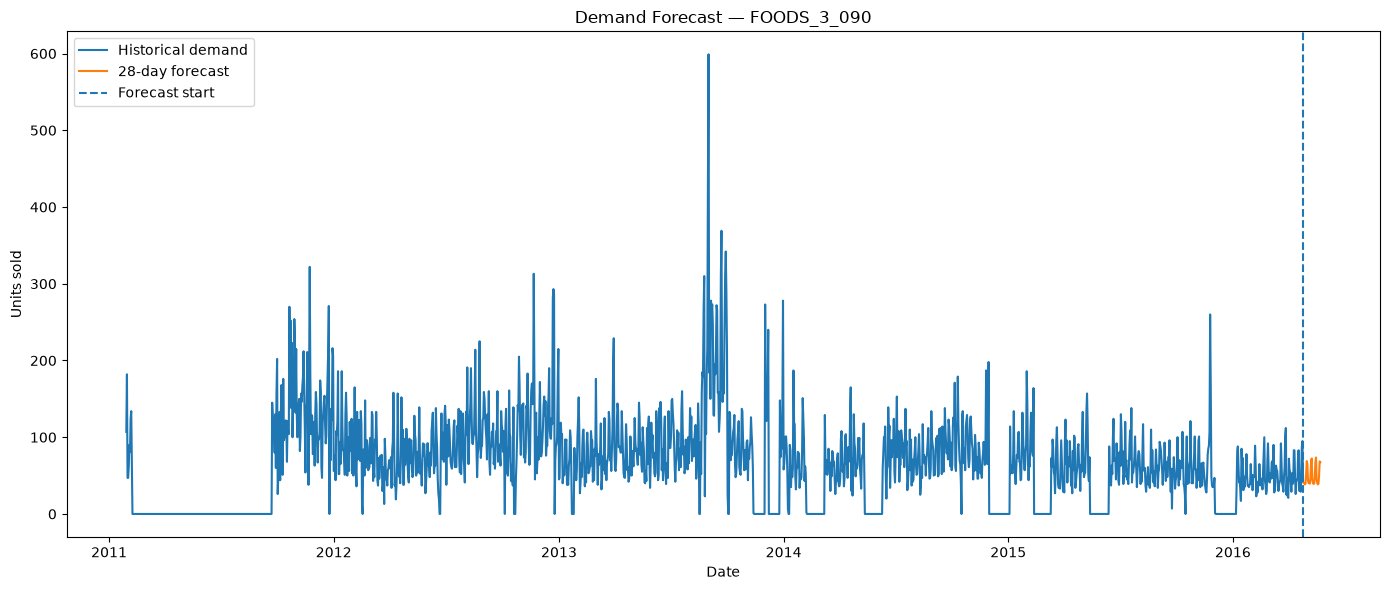

In [63]:
selected_item = "FOODS_3_090"

historical_plot = sales_long[
    sales_long["item_id"] == selected_item
].copy()

forecast_plot = future_predictions[
    future_predictions["item_id"] == selected_item
].copy()

plt.figure(figsize=(14, 6))

plt.plot(
    historical_plot["date"],
    historical_plot["sales"],
    label="Historical demand"
)

plt.plot(
    forecast_plot["date"],
    forecast_plot["prediction"],
    label="28-day forecast"
)

plt.axvline(
    pd.Timestamp("2016-04-24"),
    linestyle="--",
    label="Forecast start"
)

plt.title(
    f"Demand Forecast — {selected_item}"
)

plt.xlabel("Date")
plt.ylabel("Units sold")

plt.legend()
plt.tight_layout()

plt.show()

In [64]:
forecast_table = future_predictions[
    future_predictions["item_id"] == selected_item
].copy()

forecast_table["date"] = forecast_table["date"].dt.strftime(
    "%Y-%m-%d"
)

forecast_table

,item_id,date,prediction
84,FOODS_3_090,2016-04-25,40.366003
85,FOODS_3_090,2016-04-26,39.938511
86,FOODS_3_090,2016-04-27,38.488212
87,FOODS_3_090,2016-04-28,39.533420
88,FOODS_3_090,2016-04-29,51.799025
89,FOODS_3_090,2016-04-30,68.878544
90,FOODS_3_090,2016-05-01,65.266696
91,FOODS_3_090,2016-05-02,43.645091
92,FOODS_3_090,2016-05-03,40.030093
93,FOODS_3_090,2016-05-04,39.990002


In [65]:
daily_forecast = (
    future_predictions
    .groupby("date")["prediction"]
    .sum()
    .reset_index()
)

daily_forecast.head(10)

,date,prediction
0,2016-04-25,355.698605
1,2016-04-26,345.663317
2,2016-04-27,335.866386
3,2016-04-28,339.282943
4,2016-04-29,408.997842
5,2016-04-30,531.991771
6,2016-05-01,554.902836
7,2016-05-02,391.244540
8,2016-05-03,359.283888
9,2016-05-04,357.391230


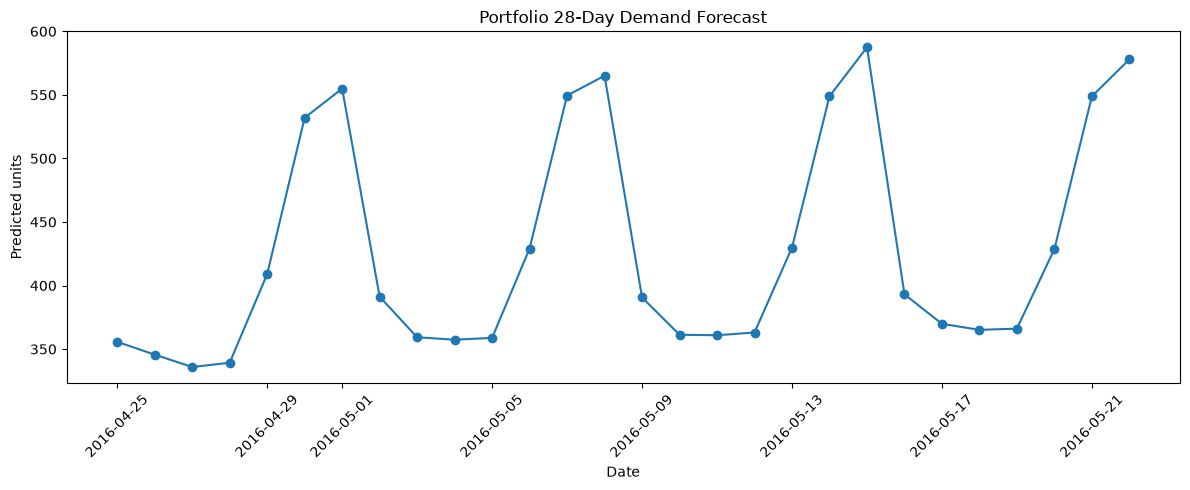

In [66]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_forecast["date"],
    daily_forecast["prediction"],
    marker="o"
)

plt.title("Portfolio 28-Day Demand Forecast")
plt.xlabel("Date")
plt.ylabel("Predicted units")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [67]:
forecast_output_path = "../reports/forecast_28_days.csv"

future_predictions.to_csv(
    forecast_output_path,
    index=False
)

print(
    f"Saved forecast to {forecast_output_path}"
)

Saved forecast to ../reports/forecast_28_days.csv


In [68]:
# ============================================================
# FINAL MODEL TRAINING
# ============================================================

from sklearn.ensemble import HistGradientBoostingRegressor

# Use all available historical data through 2016-04-24
final_train_data = model_data[
    model_data["date"] <= "2016-04-24"
].copy()

X_final = final_train_data[feature_columns]
y_final = final_train_data["sales"]

print("Final training rows:", len(final_train_data))
print("X shape:", X_final.shape)
print("y shape:", y_final.shape)
print(
    "Training period:",
    final_train_data["date"].min(),
    "to",
    final_train_data["date"].max()
)


# ------------------------------------------------------------
# Train final model
# ------------------------------------------------------------

final_model = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

final_model.fit(
    X_final,
    y_final
)

print("Final model trained successfully.")

Final training rows: 37700
X shape: (37700, 10)
y shape: (37700,)
Training period: 2011-02-26 00:00:00 to 2016-04-24 00:00:00
Final model trained successfully.


In [69]:
import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

MODEL_PATH = MODEL_DIR / "demand_forecaster.joblib"

joblib.dump(
    final_model,
    MODEL_PATH
)

print(f"Model saved to: {MODEL_PATH}")

Model saved to: ../models/demand_forecaster.joblib


In [70]:
# ============================================================
# FINAL 28-DAY FORECAST
# ============================================================

future_dates = pd.date_range(
    start="2016-04-25",
    end="2016-05-22",
    freq="D"
)

final_history = sales_long[
    sales_long["date"] <= "2016-04-24"
][
    ["item_id", "date", "sales"]
].copy()

final_predictions = recursive_forecast(
    model=final_model,
    history=final_history,
    future_dates=future_dates
)

print(
    "Forecast shape:",
    final_predictions.shape
)

print(
    final_predictions.head()
)

Forecast shape: (560, 3)
       item_id       date  prediction
0  FOODS_2_019 2016-04-25   15.262840
1  FOODS_2_019 2016-04-26   15.041208
2  FOODS_2_019 2016-04-27   14.471328
3  FOODS_2_019 2016-04-28   14.371756
4  FOODS_2_019 2016-04-29   16.741866


In [71]:
FINAL_FORECAST_PATH = Path(
    "../reports/forecast_28_days.csv"
)

final_predictions.to_csv(
    FINAL_FORECAST_PATH,
    index=False
)

print(
    f"Final forecast saved to: {FINAL_FORECAST_PATH}"
)

Final forecast saved to: ../reports/forecast_28_days.csv


In [72]:
final_predictions.describe()

,date,prediction
count,560,560.000000
mean,2016-05-08 12:00:00,21.610589
min,2016-04-25 00:00:00,1.621049
25%,2016-05-01 18:00:00,14.665218
50%,2016-05-08 12:00:00,17.418052
75%,2016-05-15 06:00:00,25.357077
max,2016-05-22 00:00:00,74.489705
std,NaN,11.646035


In [73]:
final_summary = (
    final_predictions
    .groupby("item_id")["prediction"]
    .agg(
        forecast_total="sum",
        forecast_mean="mean",
        forecast_max="max"
    )
    .sort_values(
        "forecast_total",
        ascending=False
    )
)

final_summary

,forecast_total,forecast_mean,forecast_max
item_id,,,
FOODS_3_090,1385.399662,49.478559,74.489705
FOODS_3_120,1117.428715,39.908168,57.142608
FOODS_3_586,1022.619733,36.522133,51.346048
FOODS_3_252,1018.047046,36.358823,50.750060
FOODS_3_282,614.113497,21.932625,32.223096
FOODS_3_587,573.320978,20.475749,28.749249
FOODS_2_197,570.992622,20.392594,27.072474
FOODS_3_681,559.521278,19.982903,26.700682
FOODS_3_714,555.438960,19.837106,28.080077


In [74]:
print(
    "Total forecasted units:",
    final_predictions["prediction"].sum()
)

Total forecasted units: 12101.930018796404
